# Problema 1: Regressão Linear (Usina CCPP)

Previsão da produção de energia elétrica horária (**PE**, em MW) com base em 4 variáveis ambientais:
- `AT`: Temperatura ambiente (°C)
- `V`: Vácuo no escape da turbina (cm Hg)
- `AP`: Pressão atmosférica (mbar)
- `RH`: Umidade relativa do ar (%)
- `PE`: Potência líquida gerada (MW) -> Variável alvo


### 1. Importação das Bibliotecas

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

os.makedirs('graficos', exist_ok=True)


### 2. Carregamento e Inspeção dos Dados

In [2]:
dados = pd.read_csv('dataset/ccpp.csv')
print(f"Total de registros: {dados.shape[0]} amostras, {dados.shape[1]} colunas")
dados.head()


Total de registros: 9568 amostras, 5 colunas


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


#### Verificação de Valores Ausentes

In [3]:
print("Valores nulos por coluna:")
print(dados.isnull().sum())
dados.describe().round(2)


Valores nulos por coluna:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64


,AT,V,AP,RH,PE
count,9568.00,9568.00,9568.00,9568.00,9568.00
mean,19.65,54.31,1013.26,73.31,454.37
std,7.45,12.71,5.94,14.60,17.07
min,1.81,25.36,992.89,25.56,420.26
25%,13.51,41.74,1009.10,63.33,439.75
50%,20.34,52.08,1012.94,74.97,451.55
75%,25.72,66.54,1017.26,84.83,468.43
max,37.11,81.56,1033.30,100.16,495.76


### 3. Tarefa 1: Correlação entre Variáveis Independentes e a Variável Alvo (PE)
Calculamos o coeficiente de correlação de Pearson entre cada sensor ambiental e a potência gerada ($PE$).


In [4]:
correlacoes = dados.corr()
correlacao_pe = correlacoes['PE'].drop('PE').sort_values()
print("Correlação com a produção de energia (PE):")
for var, val in correlacao_pe.items():
    print(f"- {var:4s}: {val:+.4f}")


Correlação com a produção de energia (PE):
- AT  : -0.9481
- V   : -0.8698
- RH  : +0.3898
- AP  : +0.5184


#### Gráfico: Matriz de Correlação
Visualizamos as relações lineares através de um mapa de calor.


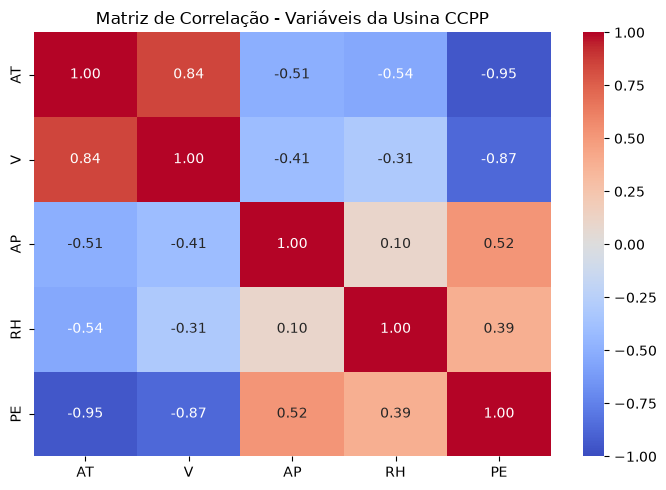

In [5]:
plt.figure(figsize=(7, 5))
sns.heatmap(correlacoes, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de Correlação - Variáveis da Usina CCPP')
plt.tight_layout()
plt.savefig('graficos/matriz_correlacao.png', dpi=300)
plt.show()


### 4. Tarefa 2: Correlação entre Variáveis Independentes e Multicolinearidade
Verificamos se existem relações lineares fortes entre os atributos preditores (AT, V, AP, RH).


In [6]:
var_independentes = ['AT', 'V', 'AP', 'RH']
corr_independentes = dados[var_independentes].corr()
corr_independentes.round(4)


,AT,V,AP,RH
AT,1.0000,0.8441,-0.5075,-0.5425
V,0.8441,1.0000,-0.4135,-0.3122
AP,-0.5075,-0.4135,1.0000,0.0996
RH,-0.5425,-0.3122,0.0996,1.0000


**Conclusão da Tarefa 2:**  
Existe uma correlação forte e positiva entre **AT (temperatura)** e **V (vácuo)** ($r = 0.8441$). Isso indica a presença de **multicolinearidade**. Fisicamente, quando a temperatura ambiente sobe, a temperatura da água de arrefecimento do condensador também se eleva, aumentando a pressão de condensação e o vácuo de escape da turbina a vapor.


### 5. Tarefa 3: Divisão Treino/Teste e Padronização

In [7]:
X = dados[var_independentes]
y = dados['PE']

# Divisão 80% treino (7.654) e 20% teste (1.914)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Padronização Z-score ajustada unicamente no treino
escalonador = StandardScaler()
X_train_pad = escalonador.fit_transform(X_train)
X_test_pad = escalonador.transform(X_test)

# Treinamento do modelo
modelo = LinearRegression()
modelo.fit(X_train_pad, y_train)
print("Modelo de Regressão Linear Múltipla treinado com sucesso!")


Modelo de Regressão Linear Múltipla treinado com sucesso!


### 6. Tarefa 4: Avaliação do Modelo no Conjunto de Teste (20%)

In [8]:
y_pred = modelo.predict(X_test_pad)

r2 = r2_score(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"Coeficiente de Determinação (R²): {r2:.4f} ({r2*100:.2f}%)")
print(f"RMSE (Raiz do Erro Quadrático Médio): {rmse:.4f} MW")
print(f"MAE (Erro Absoluto Médio): {mae:.4f} MW")


Coeficiente de Determinação (R²): 0.9301 (93.01%)
RMSE (Raiz do Erro Quadrático Médio): 4.5026 MW
MAE (Erro Absoluto Médio): 3.5959 MW


#### Equação de Regressão na Escala Física Original

In [9]:
modelo_orig = LinearRegression()
modelo_orig.fit(X_train, y_train)

termos = [f"({coef:+.4f} * {col})" for coef, col in zip(modelo_orig.coef_, var_independentes)]
print("Equação ajustada:")
print(f"PE = {modelo_orig.intercept_:.4f} " + " ".join(termos))


Equação ajustada:
PE = 454.5691 (-1.9859 * AT) (-0.2321 * V) (+0.0622 * AP) (-0.1581 * RH)


#### Gráfico: Valores Reais vs. Valores Previstos
Avaliamos a aderência das predições à reta perfeita de 45 graus.


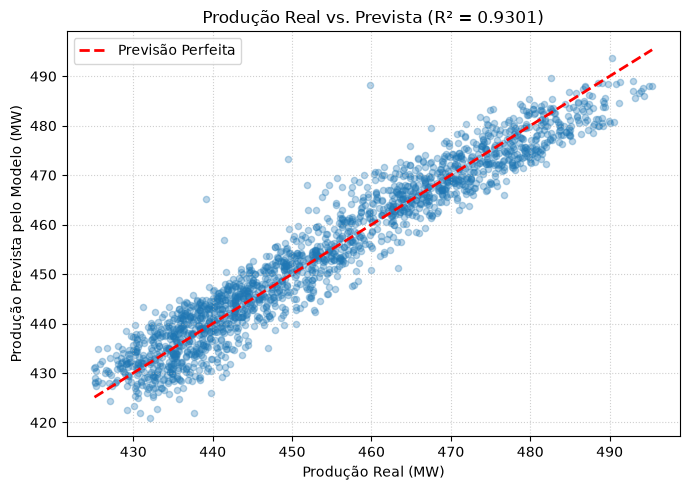

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.3, color='#1f77b4', s=20)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Previsão Perfeita')
plt.xlabel('Produção Real (MW)')
plt.ylabel('Produção Prevista pelo Modelo (MW)')
plt.title(f'Produção Real vs. Prevista (R² = {r2:.4f})')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('graficos/real_vs_previsto.png', dpi=300)
plt.show()


#### Gráfico: Distribuição dos Resíduos (Erros)
Verificamos se os resíduos apresentam distribuição aproximadamente normal e centrada em zero.


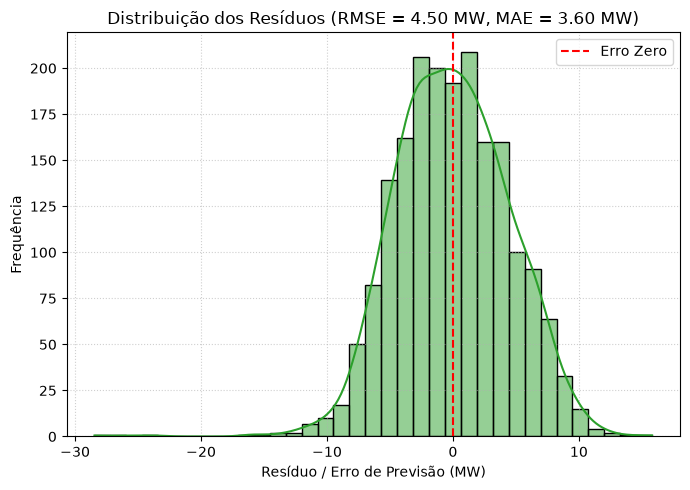

In [11]:
residuos = y_test - y_pred
plt.figure(figsize=(7, 5))
sns.histplot(residuos, kde=True, color='#2ca02c', bins=35)
plt.axvline(0, color='red', linestyle='--', label='Erro Zero')
plt.xlabel('Resíduo / Erro de Previsão (MW)')
plt.ylabel('Frequência')
plt.title(f'Distribuição dos Resíduos (RMSE = {rmse:.2f} MW, MAE = {mae:.2f} MW)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('graficos/distribuicao_residuos.png', dpi=300)
plt.show()


### Conclusão: O modelo é adequado?
**Sim, o modelo é altamente adequado.**  
1. O $R^2$ de **$93.01\%$** indica que mais de $93\%$ da variabilidade da potência líquida gerada é explicada exclusivamente por essas 4 variáveis meteorológicas.
2. O erro absoluto médio de **$3.59	ext{ MW}$** corresponde a menos de **$0.79\%$** da potência média gerada ($454	ext{ MW}$), perfeitamente adequado para planejamento de despacho energético pelo ONS.
3. Os resíduos são centrados em zero e simétricos, validando as hipóteses do modelo linear.
